# 04 Vendor cross-check

*To write: what question this notebook answers, and the one-paragraph conclusion.*

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from optionslib.chain import compare_to_vendor, invert_chain, read_options_csv, status_table
from optionslib.vol.implied import NormalizedProblem, Reason, implied_vol, normalized_price

warnings.simplefilter("ignore", RuntimeWarning)

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = REPO / "data" / "2022-07-01_options.csv"
FIGURES = REPO / "figures"
FIGURES.mkdir(exist_ok=True)

AM_SHIFT_DAYS = 17.5 / 24  # Thursday 16:00 close to Friday 09:30 settlement print

chain = read_options_csv(DATA)  # AM contracts end at the 09:30 open (our convention)
res, fwd = invert_chain(chain, with_bid_ask=False)
res["days"] = res["T"] * 365
print(f"{len(res):,} contracts, {int((fwd.status == 'OK').sum())} expiries with a parity forward")

19,552 contracts, 50 expiries with a parity forward


## 1. Where every row ended up, against the vendor's iv_flag

*To write: which of our categories map one-to-one onto theirs, and which do not.*

In [2]:
status_table(res)

vendor_iv_flag,vendor_flag_0,vendor_flag_1,vendor_flag_2,vendor_flag_3,vendor_flag_5,vendor_flag_6,All
quote_status,,,,,,,
EXPIRED,0,0,0,0,0,510,510
NO_FORWARD,0,11,0,0,3,0,14
OK/BELOW_FLOOR,7,0,0,322,0,0,329
OK/OK,16914,0,0,1017,0,0,17931
ONE_SIDED,0,0,768,0,0,0,768
All,16921,11,768,1339,3,510,19552


## 2. IV agreement under our conventions

*To write: the headline agreement, and why AM and PM contracts look so different.*

In [3]:
solved = (res.reason == Reason.OK) & (res.vendor_iv_flag == 0)


def agreement(frame, mask):
    """|our IV - vendor IV| on rows in mask that both of us solved with a parity forward."""
    both = mask & (frame.reason == Reason.OK) & (frame.vendor_iv_flag == 0)
    d = (frame.iv - frame.vendor_iv).abs()[both]
    return {"n": len(d), "median |diff|": d.median(), "p90 |diff|": d.quantile(0.9), "within 1e-4": (d <= 1e-4).mean()}


by_settlement = pd.DataFrame({st: agreement(res, res.settlement_time == st) for st in ("PM", "AM")}).T
overall = compare_to_vendor(res)
print(f"all solved rows: n = {overall['n']:,}, median |diff| = {overall['abs_diff']['median']:.2e}, "
      f"mean signed diff = {overall['mean_signed_diff']:+.2e}")
by_settlement

all solved rows: n = 16,914, median |diff| = 3.78e-04, mean signed diff = +2.58e-03


,n,median |diff|,p90 |diff|,within 1e-4
PM,10715.0,0.000149,0.004432,0.426692
AM,6199.0,0.001050,0.010028,0.073238


## 3. Reading the gap bucket by bucket

If only the time to expiry differed, our vol and theirs would satisfy iv / vendor_iv = sqrt(T_vendor / T_ours), so the ratio
turns into an implied difference in T. Near the money, per expiry:

*To write: what the AM points show (a constant offset) and what the PM points show (a drift with maturity).*

days settlement   n  implied_dT_days
underlying expiration                                            
SPXW       2022-07-05    4.000000         PM  92         0.006104
           2022-07-06    5.000000         PM  92         0.000465
           2022-07-07    6.000000         PM  92        -0.000116
           2022-07-08    7.000000         PM  92         0.001264
           2022-07-11   10.000000         PM  92        -0.000775
           2022-07-12   11.000000         PM  92         0.009665
           2022-07-13   12.000000         PM  92        -0.000432
           2022-07-14   13.000000         PM  76         0.002329
SPX        2022-07-15   13.729167         AM  92        -0.729708
SPXW       2022-07-15   14.000000         PM  92         0.005350
           2022-07-18   17.000000         PM  90         0.009079
           2022-07-19   18.000000         PM  68         0.003203
           2022-07-20   19.000000         PM  90         0.003547
           2022-07-22   21.000000         PM  90         0.017300
           2022-07-25   24.000000         PM  92         0.004444
           2022-07-27   26.000000         PM  86         0.003280
           2022-07-29   28.000000         PM  92         0.009831
           2022-08-01   31.000000         PM  40         0.007851
           2022-08-05   35.000000         PM  92         0.041913
           2022-08-12   42.000000         PM  80         0.070573
SPX        2022-08-19   48.729167         AM  92        -0.683890
SPXW       2022-08-19   49.000000         PM  92         0.046351
           2022-08-26   56.000000         PM  52         0.100548
           2022-08-31   61.000000         PM  92         0.088281
SPX        2022-09-16   76.729167         AM  92        -0.586610
SPXW       2022-09-16   77.000000         PM  92         0.133586
           2022-09-30   91.000000         PM  92         0.186518
SPX        2022-10-21  111.729167         AM  92        -0.421999
SPXW       2022-10-21  112.000000         PM  92         0.312546
           2022-10-31  122.000000         PM  56         0.346185

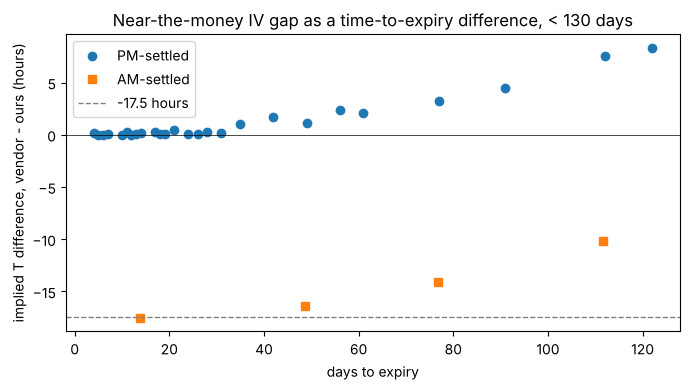

In [4]:
atm = res[solved & (res.x.abs() < 0.03)].copy()
atm["dT_days"] = atm["T"] * ((atm.iv / atm.vendor_iv) ** 2 - 1) * 365
per_bucket = (atm.groupby(["underlying", "expiration"])
              .agg(days=("days", "first"), settlement=("settlement_time", "first"), n=("iv", "size"),
                   implied_dT_days=("dT_days", "median"))
              .sort_values("days"))

# Beyond about four months the discount-rate difference (section 5) dominates the gap, and converting it to an
# equivalent T would be meaningless, so the plot stops where the time convention is the dominant effect.
short = per_bucket[per_bucket.days < 130]
fig, ax = plt.subplots(figsize=(7, 4))
for st, mk in (("PM", "o"), ("AM", "s")):
    g = short[short.settlement == st]
    ax.plot(g.days, g.implied_dT_days * 24, mk, label=f"{st}-settled")
ax.axhline(-17.5, color="grey", ls="--", lw=1, label="-17.5 hours")
ax.axhline(0, color="black", lw=0.5)
ax.set_xlabel("days to expiry")
ax.set_ylabel("implied T difference, vendor - ours (hours)")
ax.set_title("Near-the-money IV gap as a time-to-expiry difference, < 130 days")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "04_implied_dT.png", dpi=150)
per_bucket[per_bucket.days < 130]

## 4. The AM-settlement convention

The vendor appears to end AM-settled contracts at the previous trading day's close rather than at the Friday 09:30 settlement print.

*To write: what changes when we adopt their convention, and why our default is still the 09:30 print.*

In [5]:
chain_prior = read_options_csv(DATA, am_expiry="prior_close")
res_prior, _ = invert_chain(chain_prior, with_bid_ask=False)

pd.DataFrame({
    ("AM", "ours: 09:30 open"): agreement(res, res.settlement_time == "AM"),
    ("AM", "vendor: prior close"): agreement(res_prior, res_prior.settlement_time == "AM"),
    ("PM", "ours (unchanged)"): agreement(res, res.settlement_time == "PM"),
}).T

n  median |diff|  p90 |diff|  within 1e-4
AM ours: 09:30 open      6199.0       0.001050    0.010028     0.073238
   vendor: prior close   6199.0       0.000553    0.008204     0.196483
PM ours (unchanged)     10715.0       0.000149    0.004432     0.426692

## 5. The vendor's discount rate

Given our forward, find the discount factor D that makes the vendor's vol reproduce the quoted mid, near the money,
for each expiry. Compare the rate it implies with the one our parity regression measured.

*To write: what curve the vendor's rate looks like, what the 35-65 bp spread is, and why the error bars are smaller than the scatter between neighbouring short expiries (hint: what does the WLS standard error assume about errors across strikes?).*

spread beyond 20 days: median 45 bp, interquartile 39-56 bp


days   n  r_vendor_pct  r_ours_pct  se_r_pct  \
underlying expiration                                                     
SPXW       2022-07-22    21.000  62         1.271       1.985     0.056   
           2022-07-25    24.000  62         1.269       1.427     0.102   
           2022-07-27    26.000  62         1.266       1.446     0.108   
           2022-07-29    28.000  62         1.270       1.501     0.029   
           2022-08-01    31.000  32         1.274       1.425     0.077   
           2022-08-05    35.000  62         1.304       1.926     0.059   
           2022-08-12    42.000  56         1.361       2.075     0.043   
SPX        2022-08-19    48.000  62         1.403       1.808     0.013   
SPXW       2022-08-19    49.000  62         1.411       1.762     0.017   
           2022-08-26    56.000  38         1.465       2.047     0.032   
           2022-08-31    61.000  62         1.502       1.932     0.011   
SPX        2022-09-16    76.000  60         1.617       2.070     0.005   
SPXW       2022-09-16    77.000  60         1.622       2.031     0.005   
           2022-09-30    91.000  62         1.728       2.137     0.005   
SPX        2022-10-21   111.000  60         1.809       2.266     0.006   
SPXW       2022-10-21   112.000  60         1.810       2.262     0.003   
           2022-10-31   122.000  38         1.850       2.273     0.005   
SPX        2022-11-18   139.042  38         1.946       2.425     0.004   
SPXW       2022-11-18   140.042  38         1.958       2.424     0.003   
           2022-11-30   152.042  36         1.997       2.467     0.007   
SPX        2022-12-16   167.042  36         2.047       2.604     0.003   
SPXW       2022-12-30   182.042  12         2.105       2.770     0.007   
SPX        2023-01-20   202.042  12         2.173       2.812     0.006   
           2023-02-17   230.042  12         2.281       2.934     0.004   
           2023-03-17   258.000  12         2.378       3.018     0.004   
SPXW       2023-03-31   273.000  12         2.437       3.003     0.004   
SPX        2023-04-21   293.000  12         2.515       3.054     0.004   
           2023-05-19   321.000  12         2.625       3.116     0.005   
           2023-06-16   349.000  12         2.730       3.180     0.004   
SPXW       2023-06-30   364.000  12         2.788       3.124     0.008   
SPX        2023-07-21   384.000  12         2.797       3.149     0.004   
           2023-09-15   440.000  14         2.808       3.209     0.007   
           2023-12-15   531.042  12         2.826       3.257     0.006   
           2024-06-21   720.000  14         2.848       3.239     0.006   
           2024-12-20   902.042   4         2.866       3.268     0.017   
           2025-12-19  1266.042   4         2.879       3.171     0.016   
           2026-12-18  1630.042   2         2.895       3.129     0.019   

                       spread_bp  
underlying expiration             
SPXW       2022-07-22     71.473  
           2022-07-25     15.756  
           2022-07-27     18.035  
           2022-07-29     23.066  
           2022-08-01     15.065  
           2022-08-05     62.127  
           2022-08-12     71.489  
SPX        2022-08-19     40.513  
SPXW       2022-08-19     35.080  
           2022-08-26     58.265  
           2022-08-31     43.043  
SPX        2022-09-16     45.334  
SPXW       2022-09-16     40.854  
           2022-09-30     40.907  
SPX        2022-10-21     45.728  
SPXW       2022-10-21     45.203  
           2022-10-31     42.291  
SPX        2022-11-18     47.943  
SPXW       2022-11-18     46.643  
           2022-11-30     47.043  
SPX        2022-12-16     55.707  
SPXW       2022-12-30     66.508  
SPX        2023-01-20     63.929  
           2023-02-17     65.241  
           2023-03-17     64.049  
SPXW       2023-03-31     56.583  
SPX        2023-04-21     53.900  
           2023-05-19     49.022  
           2023-06-16     44.966  
SPXW       2023-

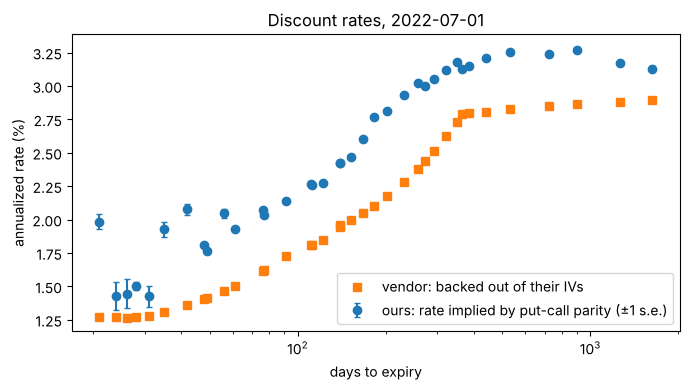

In [6]:
res["T_vendor"] = res["T"] - np.where(res.settlement_time == "AM", AM_SHIFT_DAYS / 365, 0.0)
near = res[solved & (res.x.abs() < 0.02)].copy()
near["b_vendor"] = [normalized_price(x, int(cp), v * np.sqrt(t))
                    for x, cp, v, t in zip(near.x, near.call_or_put, near.vendor_iv, near.T_vendor)]
near["D_vendor"] = near["mid"] / (np.sqrt(near.F * near.strike) * near.b_vendor)
rates = (near.groupby(["underlying", "expiration"])
         .agg(T_vendor=("T_vendor", "first"), D=("D", "first"), D_vendor=("D_vendor", "median"), n=("D_vendor", "size")))
rates["days"] = rates.T_vendor * 365
rates["r_ours_pct"] = -np.log(rates.D) / rates.T_vendor * 100
rates["r_vendor_pct"] = -np.log(rates.D_vendor) / rates.T_vendor * 100
rates["spread_bp"] = (rates.r_ours_pct - rates.r_vendor_pct) * 100
rates = rates.join(fwd.set_index(["underlying", "expiration"])["se_r"]).sort_values("days")
rates["se_r_pct"] = rates.se_r * 100
shown = rates[rates.days > 20]

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(shown.days, shown.r_ours_pct, yerr=shown.se_r_pct, fmt="o", capsize=2,
            label="ours: rate implied by put-call parity (±1 s.e.)")
ax.plot(shown.days, shown.r_vendor_pct, "s", label="vendor: backed out of their IVs")
ax.set_xscale("log")
ax.set_xlabel("days to expiry")
ax.set_ylabel("annualized rate (%)")
ax.set_title("Discount rates, 2022-07-01")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "04_discount_rates.png", dpi=150)
print(f"spread beyond 20 days: median {shown.spread_bp.median():.0f} bp, "
      f"interquartile {shown.spread_bp.quantile(.25):.0f}-{shown.spread_bp.quantile(.75):.0f} bp")
shown[["days", "n", "r_vendor_pct", "r_ours_pct", "se_r_pct", "spread_bp"]].round(3)

## 6. Out-of-sample: both vendor conventions imposed

The vendor discount factors above were fitted on strikes with |x| < 0.02 only. Impose them, together with the vendor's
AM convention, and test on strikes the fit never saw.

*To write: what is left of the gap once both conventions are matched, and what that says about the solver and the forward.*

In [7]:
test = res[solved & (res.x.abs() > 0.05) & (res.x.abs() < 0.5)].join(rates["D_vendor"], on=["underlying", "expiration"], how="inner")
test["iv_vendor_conventions"] = [
    implied_vol(NormalizedProblem(T=t, K=k, F=f, D=d, call_or_put=int(cp)), m).sigma
    for t, k, f, d, cp, m in zip(test.T_vendor, test.strike, test.F, test.D_vendor, test.call_or_put, test["mid"])]
oos = pd.DataFrame({
    label: {"n": len(d), "median |diff|": d.median(), "p90 |diff|": d.quantile(0.9),
            "within 1e-4": (d <= 1e-4).mean(), "within 1e-5": (d <= 1e-5).mean()}
    for label, d in (("our conventions", (test.iv - test.vendor_iv).abs()),
                     ("vendor conventions", (test.iv_vendor_conventions - test.vendor_iv).abs()))}).T
oos

,n,median |diff|,p90 |diff|,within 1e-4,within 1e-5
our conventions,11183.0,0.000647,0.008960,0.266565,0.036126
vendor conventions,11183.0,0.000048,0.001133,0.622105,0.170169


## 7. Which discounting is consistent with the quotes?

Under the correct forward and discount factor, a call and a put at the same strike carry one implied vol. The gap between
them needs no outside reference. Compare it for our vols and for the vendor's, near the money.

*To write: why this test decides between the two discount rates, and the result.*

In [8]:
def call_put_gap(frame, column, mask):
    s = frame[mask]
    wide = s.pivot_table(index=["underlying", "expiration", "strike"], columns="call_or_put", values=column, aggfunc="first").dropna()
    gap = (wide[1] - wide[-1]).rename("gap").reset_index()
    return gap.merge(frame.groupby(["underlying", "expiration"]).T.first().reset_index(), on=["underlying", "expiration"])

mask = solved & (res.x.abs() < 0.10)
rows = {}
for label, col in (("ours", "iv"), ("vendor", "vendor_iv")):
    g = call_put_gap(res, col, mask)
    long = g[g["T"] > 0.25]
    rows[label] = {"strikes": len(g), "median |gap| all": g.gap.abs().median(),
                   "strikes T>3m": len(long), "median |gap| T>3m": long.gap.abs().median(),
                   "median signed gap T>3m": long.gap.median()}
pc = pd.DataFrame(rows).T
print(f"beyond 3 months the vendor's call-put gap is {pc.loc['vendor', 'median |gap| T>3m'] / pc.loc['ours', 'median |gap| T>3m']:.1f}x ours")
pc

beyond 3 months the vendor's call-put gap is 5.1x ours


,strikes,median |gap| all,strikes T>3m,median |gap| T>3m,median signed gap T>3m
ours,4168.0,0.000130,1156.0,0.000076,-0.000027
vendor,4168.0,0.000349,1156.0,0.000391,0.000083


## 8. Quotes the vendor rejects as below the no-arbitrage floor

We solve about a thousand quotes that the vendor flags as violating the lower bound (their flag 3).

*To write: why a lower discount rate raises the floor, and which classification is consistent with the quotes.*

In [9]:
f3 = res[(res.reason == Reason.OK) & (res.vendor_iv_flag == 3)].join(rates["D_vendor"], on=["underlying", "expiration"], how="left")
intrinsic = np.maximum(f3.call_or_put * (f3.F - f3.strike), 0)
between = (f3["mid"] > f3.D * intrinsic) & (f3["mid"] <= f3.D_vendor * intrinsic)
print(f"vendor flag 3, solved by us: {len(f3):,}")
print(f"  mid above our floor and at or below the floor under the vendor's discount factor: "
      f"{int(between.sum()):,} ({between[f3.D_vendor.notna()].mean():.1%})")
print(f"  in the money by more than 5% in log-moneyness: {((f3.x * f3.call_or_put) > 0.05).mean():.1%}")
print(f"  median time value above our floor: ${(f3['mid'] - f3.D * intrinsic).median():.2f}")

vendor flag 3, solved by us: 1,017
  mid above our floor and at or below the floor under the vendor's discount factor: 976 (96.0%)
  in the money by more than 5% in log-moneyness: 100.0%
  median time value above our floor: $0.44


## 9. One contract, under both conventions

*To write: walk through this contract and account for the difference from the vendor's vol.*

In [10]:
def pick(frame):
    return frame[(frame.contract == "SPX220819C03825000")].iloc[0]

ours, theirs = pick(res), pick(res_prior)
print(f"{ours.contract}: K = {ours.strike:.0f}, mid = {ours['mid']:.2f}, F = {ours.F:.3f}, D = {ours.D:.6f}")
print(f"  ours   (09:30 open)   T = {ours['T'] * 365:.3f} days  sigma = {ours.iv:.6f}")
print(f"  vendor convention     T = {theirs['T'] * 365:.3f} days  sigma = {theirs.iv:.6f}")
print(f"  vendor's own                               sigma = {ours.vendor_iv:.6f}")
print(f"  time rescaling predicts {ours.iv * np.sqrt(ours['T'] / theirs['T']):.6f}; remaining gap "
      f"{theirs.iv - ours.vendor_iv:+.6f} is the discount-rate difference")

SPX220819C03825000: K = 3825, mid = 135.20, F = 3823.659, D = 0.997625
  ours   (09:30 open)   T = 48.729 days  sigma = 0.244388
  vendor convention     T = 48.000 days  sigma = 0.246238
  vendor's own                               sigma = 0.246210
  time rescaling predicts 0.246238; remaining gap +0.000028 is the discount-rate difference


## Summary

*To write: the findings in three or four sentences.*

In [11]:
summary = pd.Series({
    "contracts": len(res),
    "solved": int((res.reason == Reason.OK).sum()),
    "AM convention difference (hours)": 17.5,
    "median discount-rate spread beyond 20 days (bp)": round(shown.spread_bp.median(), 1),
    "out-of-sample median |diff|, our conventions (vol pts)": round(oos.loc["our conventions", "median |diff|"] * 100, 4),
    "out-of-sample median |diff|, vendor conventions (vol pts)": round(oos.loc["vendor conventions", "median |diff|"] * 100, 4),
    "call-put |gap| T>3m, ours (vol pts)": round(pc.loc["ours", "median |gap| T>3m"] * 100, 4),
    "call-put |gap| T>3m, vendor (vol pts)": round(pc.loc["vendor", "median |gap| T>3m"] * 100, 4),
})
summary

contracts                                                    19552.0000
solved                                                       17931.0000
AM convention difference (hours)                                17.5000
median discount-rate spread beyond 20 days (bp)                 45.0000
out-of-sample median |diff|, our conventions (vol pts)           0.0647
out-of-sample median |diff|, vendor conventions (vol pts)        0.0048
call-put |gap| T>3m, ours (vol pts)                              0.0076
call-put |gap| T>3m, vendor (vol pts)                            0.0391
dtype: float64